In [1]:
###--------------------------------------------LOAD LIBRARIES
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import copy

In [2]:
adata =  sc.read("/home/MRMelissaGrantPeters/MinaRyten/Melissa/spatialDLPFC/nonIF_c2l_anndata_combined_30samples.h5ad")


In [3]:
# Prepare data

subset = adata[adata.obs['bayesSpace_harmony_7'].isin([1,2,3,4,6])]   # Excluding WM and meningeal layers

subset.obs['bayesSpace_harmony_7'] = subset.obs['bayesSpace_harmony_7'].replace({   # Renaming to match order of MRI (L1, closer to WM, L4 closer to meninges)
                                                     1 : 'SpD1',
                                                     2 : 'SpD1', 
                                                     3 : 'SpD2', 
                                                     4 : 'SpD3',
                                                     6 : 'SpD4'})

subset.obs['sample_id'] = subset.obs['sample_id'].astype(str)

df_deconvo = subset.obs[np.isnan(subset.obs['Oligo'])==False]

deconvo = ['Astro',
 'EndoMural',
 'Excit_L2_3',
 'Excit_L3',
 'Excit_L3_4_5',
 'Excit_L4',
 'Excit_L5',
 'Excit_L5_6',
 'Excit_L6',
 'Inhib',
 'Micro',
 'OPC',
 'Oligo']

probs = subset.obs[['Astro', 'EndoMural', 'Micro', 'Oligo', 'OPC', 'Excit_L2_3', 'Excit_L3',
       'Excit_L3_4_5', 'Excit_L4', 'Excit_L5', 'Excit_L5_6', 'Excit_L6',
       'Inhib']]
hot1 = copy.copy(probs)
hot1.iloc[:,:] = 0
for m in range (0,np.shape(probs)[0]):
    hot1.iloc[m,:][probs.T[probs.index[m]].nlargest(3).index]=1

annotated = hot1.merge(subset.obs[['sample_id','bayesSpace_harmony_7']], left_index = True, right_index = True, how = 'inner')
annotated = annotated.groupby(['sample_id', 'bayesSpace_harmony_7']).sum().reset_index().melt(id_vars = ['sample_id', 'bayesSpace_harmony_7'])

/tmp/ipykernel_2177779/3314865330.py:5: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  subset.obs['bayesSpace_harmony_7'] = subset.obs['bayesSpace_harmony_7'].replace({   # Renaming to match order of MRI (L1, closer to WM, L4 closer to meninges)


In [4]:
annotated.to_csv('../../processed_data/01b-4layers_withendo/02-top3_cells_counts/top3_cells_per_layer_count.csv')

celllist = ['Astro', 'EndoMural', 'Micro', 'Oligo', 'OPC', 'Excit_L2_3', 'Excit_L3',
       'Excit_L3_4_5', 'Excit_L4', 'Excit_L5', 'Excit_L5_6', 'Excit_L6',
       'Inhib']
for cell in celllist:
    subset = annotated[annotated['variable']==cell]
    pivot = subset.pivot(index='sample_id', columns='bayesSpace_harmony_7', values='value')
    pivot.to_csv('../../processed_data/01b-4layers_withendo/02-top3_cells_counts/count_%s_4SpD_withEndo.csv' % cell)

In [5]:
custom_palette = {
    'SpD1': '#ED5E70', 
    'SpD2': '#CCBB44',  
    'SpD3': '#238934',  
    'SpD4': '#66CCEE'   
}

Astro


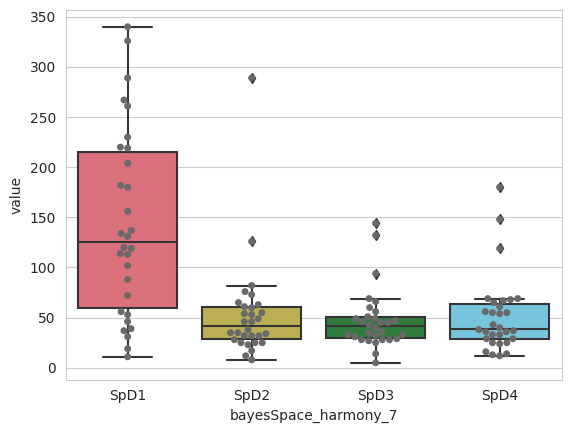

EndoMural


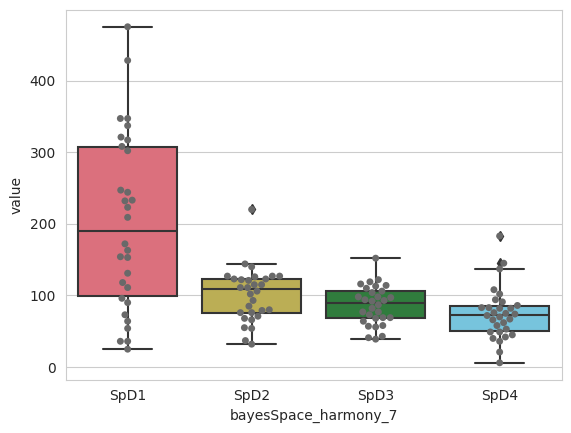

Micro


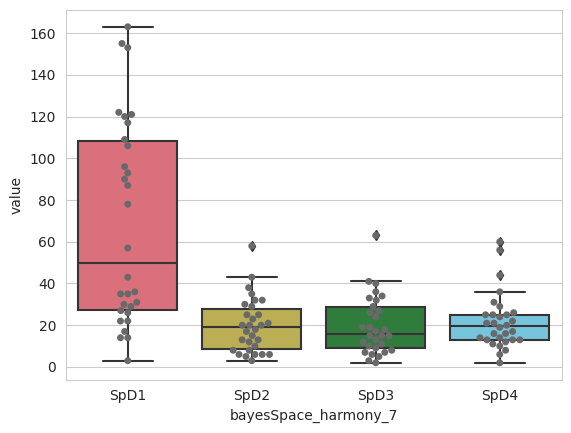

Oligo


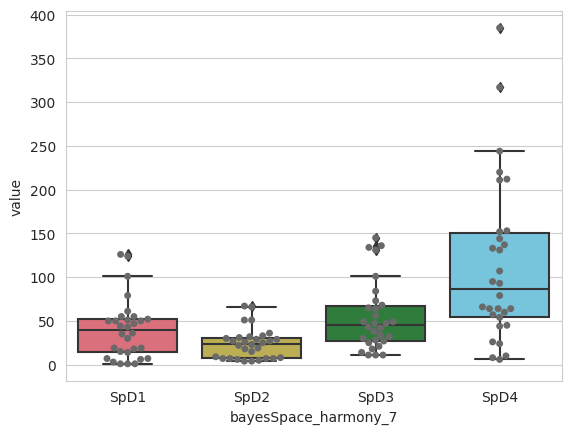

OPC


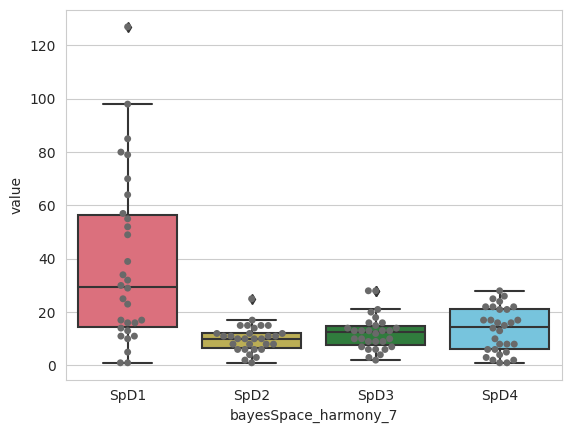

Excit_L2_3


/home/MRMelissaGrantPeters/miniconda3/envs/panpipes-hardy/lib/python3.8/site-packages/seaborn/categorical.py:1296: UserWarning: 36.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/home/MRMelissaGrantPeters/miniconda3/envs/panpipes-hardy/lib/python3.8/site-packages/seaborn/categorical.py:1296: UserWarning: 43.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/home/MRMelissaGrantPeters/miniconda3/envs/panpipes-hardy/lib/python3.8/site-packages/seaborn/categorical.py:1296: UserWarning: 50.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


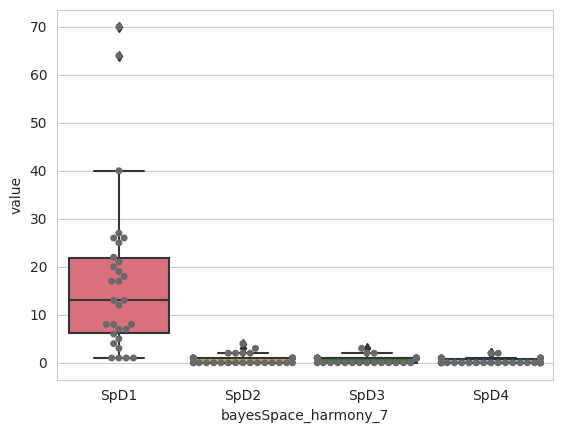

Excit_L3


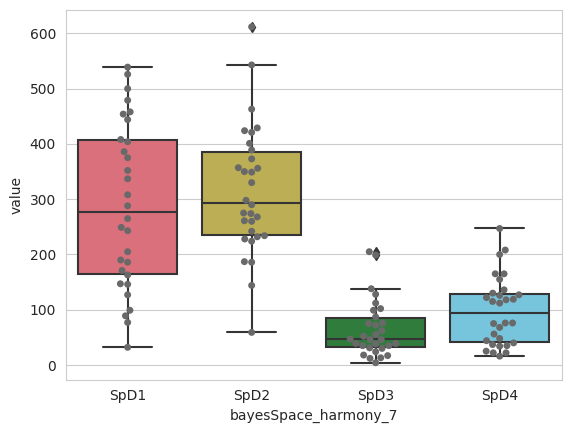

Excit_L3_4_5


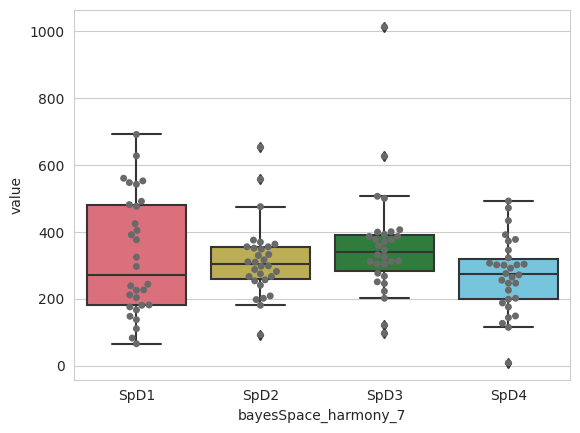

Excit_L4


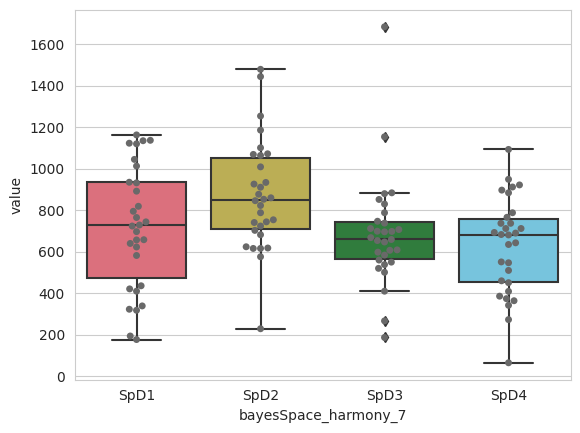

Excit_L5


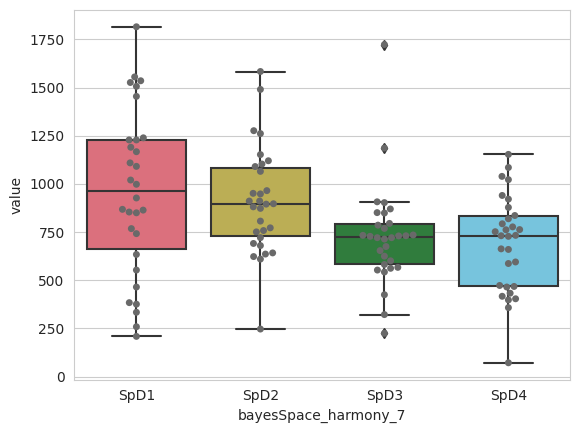

Excit_L5_6


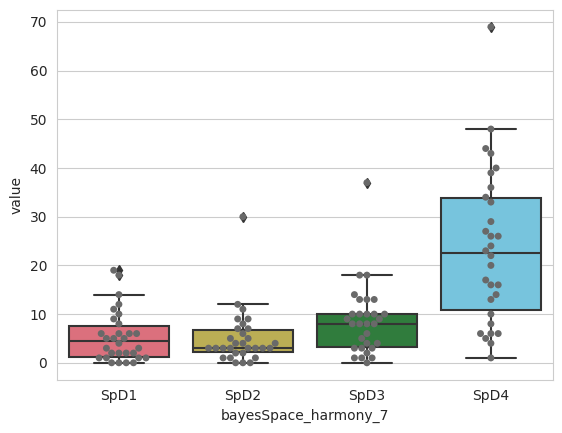

Excit_L6


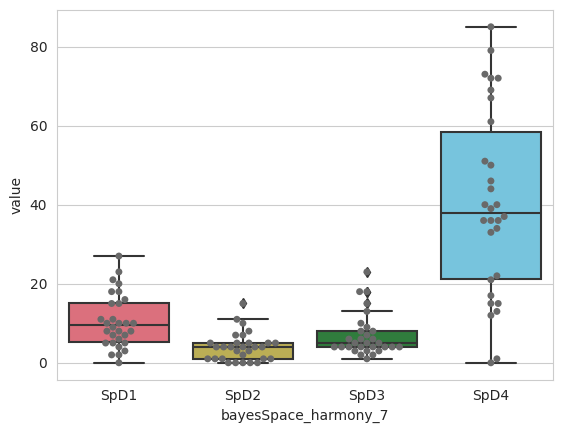

Inhib


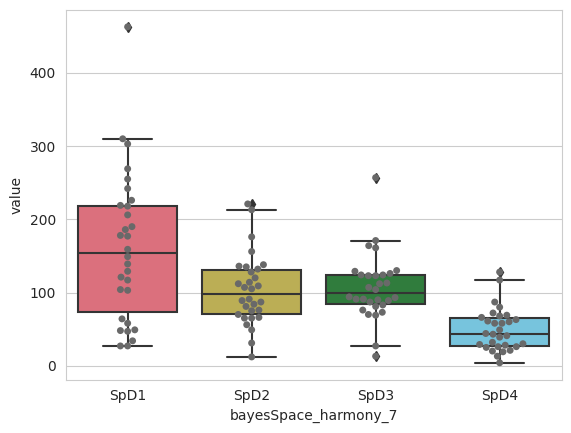

In [7]:
sns.set_style('whitegrid')

for cell in ['Astro', 'EndoMural', 'Micro', 'Oligo', 'OPC', 'Excit_L2_3', 'Excit_L3',
       'Excit_L3_4_5', 'Excit_L4', 'Excit_L5', 'Excit_L5_6', 'Excit_L6',
       'Inhib']:
    print(cell)
    sns.boxplot(data = annotated[annotated['variable']==cell], x = 'bayesSpace_harmony_7', y = 'value', palette = custom_palette)
    sns.swarmplot(data = annotated[annotated['variable']==cell], x = 'bayesSpace_harmony_7', y = 'value', color = 'dimgrey')
    plt.savefig('../../plots/01b-4layers_withendo/02-top3_cells_counts/top3_counts_%s.png' % cell)
    plt.show()